# Hotel Booking Cancellation Prediction
### Logistic Regression Classifier

In this notebook, I've done the basic EDA, feature engineering & built the baseline model for the Logistic Regression Clasiffier for the `isCancelled` feature.

What's left to be done? hyperparameter tuning & use of PCA / LDA.

## Loading Data
### Library Imports

In [8]:
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             RocCurveDisplay, accuracy_score)

RANDOM_STATE = 42

In [9]:
df = pd.read_csv('/content/H2.csv')
df.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [10]:
df.shape

(79330, 31)

## Data Cleaning
### Feature Format
removing padding from string data


In [11]:
for feature in ['Meal', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'Agent', 'Company']:
    if pd.api.types.is_string_dtype(df[feature]):   # Agent/Company can load as numeric when NULL is read as NaN
        df[feature] = df[feature].str.strip()

### Missing Data

In [12]:
df.isnull().sum()[lambda s: s > 0]

,0
Children,4
Country,24


According to the source paper, `NULL` in `Agent` and `Company` means "not applicable", not missing data. This means that the `NULL` values do have semantic data and should not be immediately dropped.

In [13]:
df['Agent'] = df['Agent'].replace('NULL', np.nan).fillna('No Agent').astype(str)
df['Company'] = df['Company'].replace('NULL', np.nan).fillna('No Company').astype(str)
df = df.dropna(subset=['Children'])
df['Country'] = df['Country'].fillna('unknown')
df.isnull().sum().sum()

np.int64(0)

### Data Types

In [14]:
df['Children'] = df['Children'].astype(int)
df['ReservationStatusDate'] = pd.to_datetime(df['ReservationStatusDate'])
df.dtypes

,0
IsCanceled,int64
LeadTime,int64
ArrivalDateYear,int64
ArrivalDateMonth,object
ArrivalDateWeekNumber,int64
ArrivalDateDayOfMonth,int64
StaysInWeekendNights,int64
StaysInWeekNights,int64
Adults,int64
Children,int64


### Duplicates

In [15]:
print(f'Duplicated rows: {df.duplicated().sum():,} ({df.duplicated().mean():.1%})')

Duplicated rows: 25,902 (32.7%)


There are 26K duplicates in the data. However there is no true primary key / discriminating feature to count these rows out. Especially as this dataset is real (and research-quality).

> this was addressed in the preprocessing stage but it's hard to avoid doing basic preprocessing for each model as well

### Feature Engineering

In [16]:
month_map = {m: i for i, m in enumerate(['January', 'February', 'March', 'April', 'May', 'June', 'July',
                                         'August', 'September', 'October', 'November', 'December'], start=1)}
df['ArrivalDateFull'] = pd.to_datetime(dict(year=df['ArrivalDateYear'],
                                              month=df['ArrivalDateMonth'].map(month_map),
                                              day=df['ArrivalDateDayOfMonth']))

# Days between arrival date and last status change:
# (will be used for visualization only. Arrival date to3tabar leakage brdo)
df['StatusMinusArrivalDate'] = (df['ArrivalDateFull'] - df['ReservationStatusDate']).dt.days.abs()

# Total nights = weekends + weekdays (wow who would've thought)
df['TotalNights'] = df['StaysInWeekendNights'] + df['StaysInWeekNights']

## EDA
### Target Variable: Cancellation

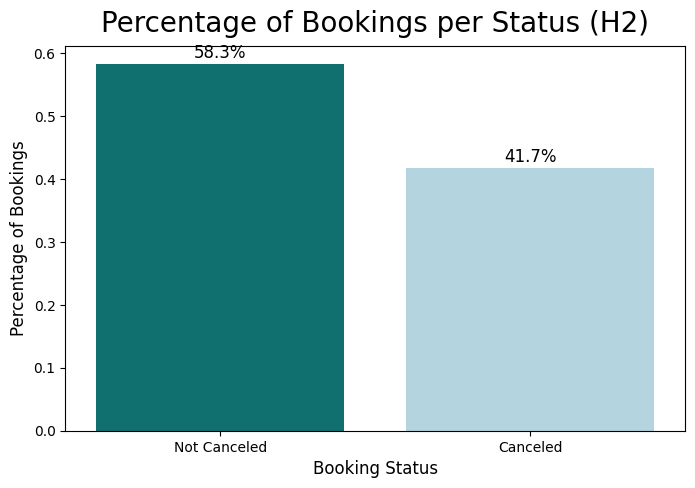

In [17]:
rate = df['IsCanceled'].value_counts(normalize=True).sort_index()
plt.figure(figsize=(8,5))
plt.title('Percentage of Bookings per Status (H2)', fontsize=20, pad=10)
sns.barplot(x=['Not Canceled', 'Canceled'], y=rate.values, hue=['Not Canceled', 'Canceled'],
            palette=['teal', 'lightblue'], legend=False)
plt.ylabel('Percentage of Bookings', fontsize=12)
plt.xlabel('Booking Status', fontsize=12)
for i, v in enumerate(rate.values):
    plt.text(i, v + 0.01, f'{v:.1%}', ha='center', fontsize=12);

41.7% of the bookings were canceled, which compared to the H1 dataset (yes I looked at it), is a higher percentage. This means that we can expect accuracy that is slightly lower compared to models trained on both datasets.

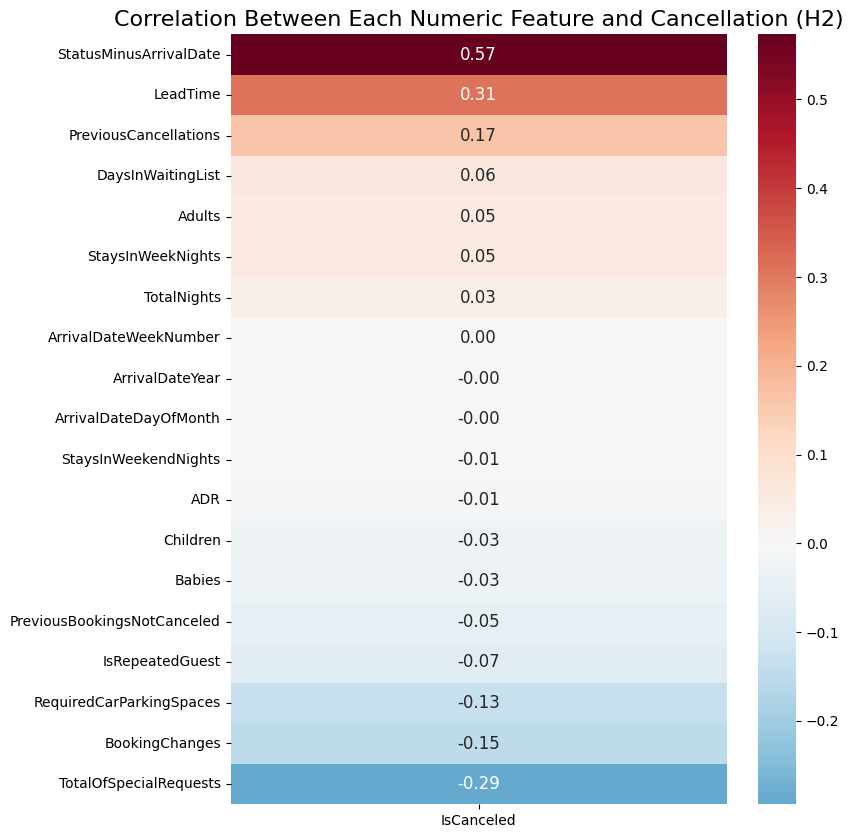

In [18]:
corr = df.select_dtypes('number').corr()[['IsCanceled']].drop('IsCanceled').sort_values('IsCanceled', ascending=False)
plt.figure(figsize=(8,10))
ax = sns.heatmap(corr, annot=True, annot_kws={'size': 12}, cmap='RdBu_r', center=0, fmt='.2f')
ax.set_title('Correlation Between Each Numeric Feature and Cancellation (H2)', fontsize=16);

Lots to unpack here:
- `StatusMinusArrivalDate` tops the chart at +0.57, which heavily indicates leakage; which semantically makes sense because it is derived from the outcome date.
- `LeadTime` +0.31 and `TotalOfSpecialRequests` −0.29 are the strongest correlates of isCancelled which can be considered as fair / non-leaking features.
- `PreviousCancellations` +0.17 is next. A history of canceling predicts canceling again.
- attributes likes total of special requests, required car parking spaces and booking changes have strong negative correlations. My interpretation of this is that when customer invest the time to figure out specifics such as parking spots / what they specifically need on the day directly maps to whether they are actually commited to going.  

ps: the `backtick` markdown effect is cool but I do not have the energy to keep using it.

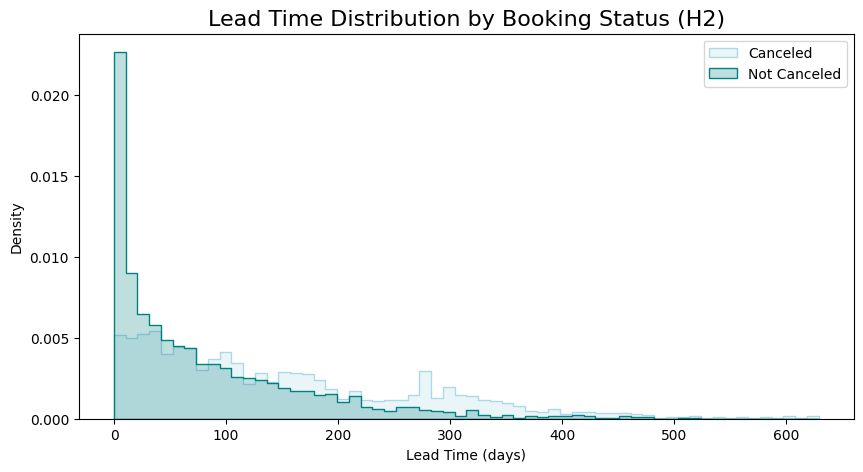

In [19]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='LeadTime', hue='IsCanceled', bins=60, stat='density', common_norm=False,
             palette=['teal', 'lightblue'], element='step')
plt.title('Lead Time Distribution by Booking Status (H2)', fontsize=16)
plt.xlabel('Lead Time (days)')
plt.legend(['Canceled', 'Not Canceled']);

The lower the lead time, the more likely a booking is to be kept. This makes sense as bookings with 0-5 days of lead time are very very very unlikely to be canceled.

Special requests & parking spaces relates to the time investment idea I mentioned before

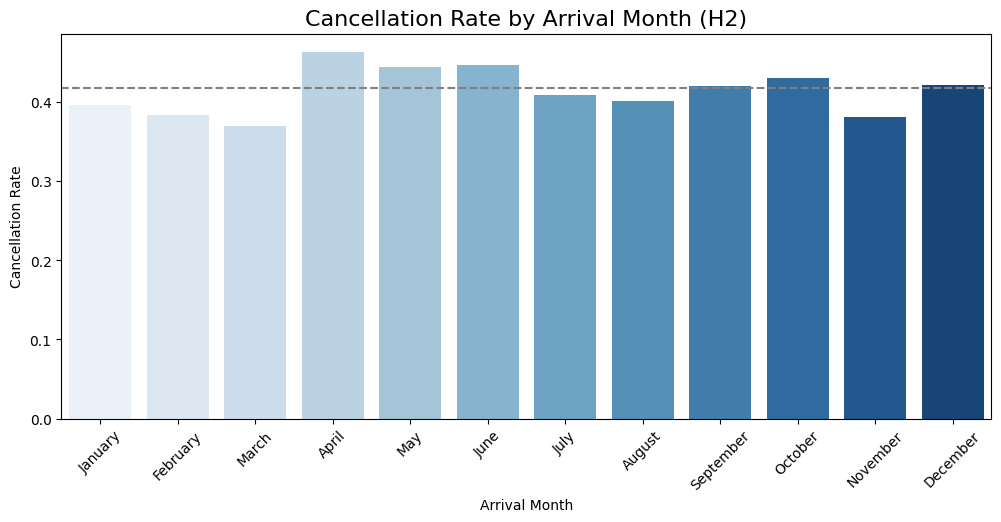

In [20]:
order = list(month_map)
m = df.groupby('ArrivalDateMonth')['IsCanceled'].mean().reindex(order)
plt.figure(figsize=(12,5))
sns.barplot(x=m.index, y=m.values, hue=m.index, palette='Blues', legend=False)
plt.axhline(df['IsCanceled'].mean(), ls='--', color='grey')
plt.xticks(rotation=45)
plt.ylabel('Cancellation Rate')
plt.xlabel('Arrival Month')
plt.title('Cancellation Rate by Arrival Month (H2)', fontsize=16);

**Interpretation:** bookings peak in spring and summer. Cancellation rates are highest for April–June arrivals (44–46%) and lowest for March, November and February (37–38%). Seasonality somewhat matters but is not the most discriminating feature.

,cancel_rate,n_bookings
ReservedRoomType,,
A,0.435,62595
B,0.328,1111
C,0.357,14
D,0.352,11768
E,0.325,1553
F,0.391,1791
G,0.246,484
P,1.000,10


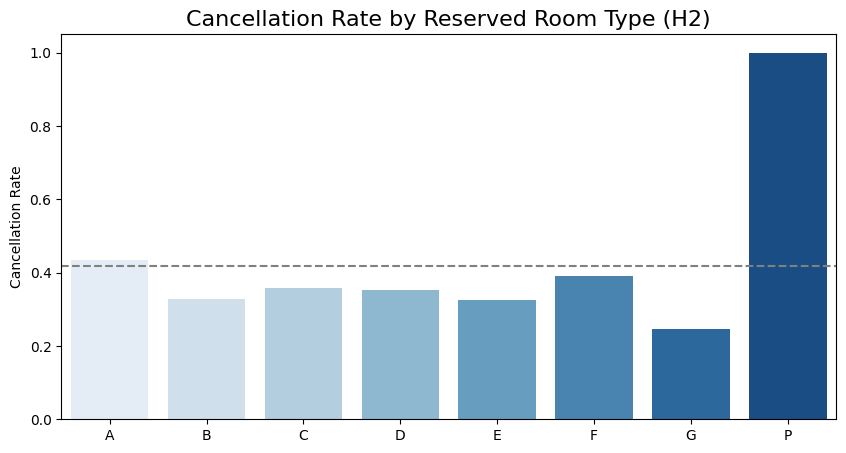

In [21]:
def cancel_rate_plot(col, title, order=None):
    g = df.groupby(col)['IsCanceled'].agg(['mean', 'size'])
    if order is not None:
        g = g.reindex(order)
    plt.figure(figsize=(10,5))
    sns.barplot(x=g.index.astype(str), y=g['mean'], hue=g.index.astype(str), palette='Blues', legend=False)
    plt.axhline(df['IsCanceled'].mean(), ls='--', color='grey')
    plt.title(title, fontsize=16)
    plt.ylabel('Cancellation Rate')
    plt.xlabel('')
    return g.rename(columns={'mean': 'cancel_rate', 'size': 'n_bookings'}).round(3)

cancel_rate_plot('ReservedRoomType', 'Cancellation Rate by Reserved Room Type (H2)')

There are only 10 bookings of room type P, so this cancellation doesn't mean much.

,cancel_rate,n_bookings
DepositType,,
No Deposit,0.305,66438
Non Refund,0.998,12868
Refundable,0.700,20


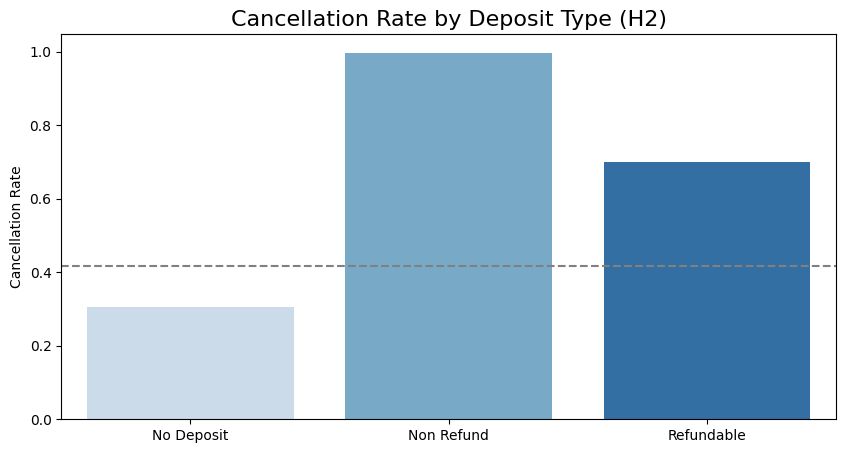

In [22]:
cancel_rate_plot('DepositType', 'Cancellation Rate by Deposit Type (H2)')

A counter intuitive pattern appears when we look at the % of cancellation in non refundable bookings.

The pattern in the data indicates that customers are more likely to cancel bookings when the booking is non-refundable. This is extremely counter intuitive and needs looking into

In [23]:
# Digging into the counter-intuitive non-refundable result: who books non-refundable deposits?
for col in ['MarketSegment', 'CustomerType', 'DistributionChannel']:
    display(pd.crosstab(df['DepositType'], df[col], normalize='index').round(3))
display(df.groupby('DepositType')[['LeadTime', 'PreviousCancellations', 'TotalOfSpecialRequests']].mean().round(2))

MarketSegment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
DepositType,,,,,,,
No Deposit,0.004,0.008,0.040,0.091,0.095,0.179,0.583
Non Refund,0.000,0.000,0.024,0.001,0.595,0.377,0.002
Refundable,0.000,0.000,0.200,0.050,0.050,0.100,0.600


CustomerType,Contract,Group,Transient,Transient-Party
DepositType,,,,
No Deposit,0.026,0.004,0.724,0.245
Non Refund,0.042,0.000,0.877,0.081
Refundable,0.000,0.000,0.650,0.350


DistributionChannel,Corporate,Direct,GDS,TA/TO
DepositType,,,,
No Deposit,0.047,0.100,0.003,0.850
Non Refund,0.022,0.011,0.000,0.967
Refundable,0.200,0.050,0.000,0.750


,LeadTime,PreviousCancellations,TotalOfSpecialRequests
DepositType,,,
No Deposit,89.00,0.05,0.65
Non Refund,216.80,0.26,0.00
Refundable,113.35,0.00,0.60


**Interpretation: (after analysis)** Non-refundable bookings are very different from the rest. 60% come through Groups and 38% through Offline TA/TO, almost none through Online TA. They have a much longer lead time (217 vs 89 days), more previous cancellations, and essentially zero special requests. This looks like a policy for block or group allocations that are routinely released, not individual guests forfeiting money.

,cancel_rate,n_bookings
MarketSegment,,
Aviation,0.219,237
Complementary,0.118,542
Corporate,0.215,2986
Direct,0.173,6092
Groups,0.689,13975
Offline TA/TO,0.428,16747
Online TA,0.374,38747


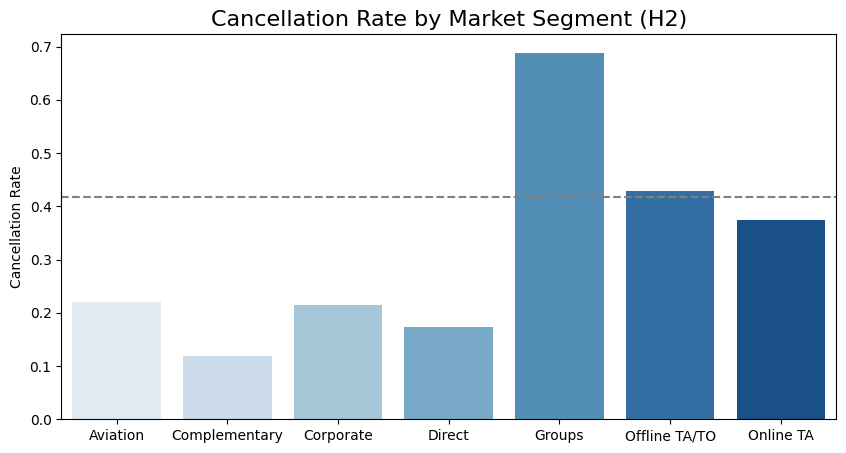

In [24]:
cancel_rate_plot('MarketSegment', 'Cancellation Rate by Market Segment (H2)')

Group bookings are much more likely to be canceled compared to complementary & corporate bookings. This is intiutive and makes sense.

,cancel_rate,n_bookings
HasPrevCancel,,
0,0.380,73937
1,0.931,5389


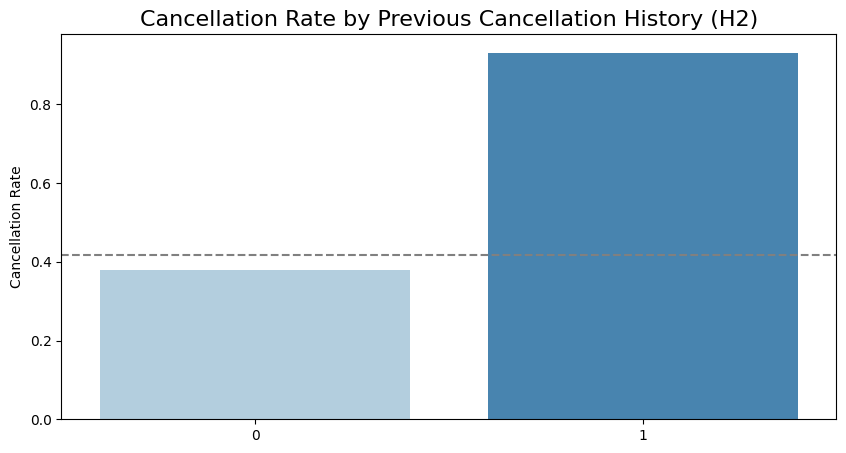

In [25]:
df['HasPrevCancel'] = (df['PreviousCancellations'] > 0).astype(int)
cancel_rate_plot('HasPrevCancel', 'Cancellation Rate by Previous Cancellation History (H2)')

customers who have a history of cancelling are more likely to cancel again (duh)

## Model Preparation
**Dropped from the feature set:**
- Columns directly related to cancellation: `IsCanceled`, `ReservationStatus`, `ReservationStatusDate`, `StatusMinusArrivalDate`
- `AssignedRoomType`: set at check-in, so not known when the booking is made
- `Agent`, `Company`: high-cardinality anonymized IDs. Their information is partly covered by `MarketSegment` and `DistributionChannel`.
- `ArrivalDateFull`: a datetime. Arrival timing is still represented by year, month (one-hot), week number and day of month.
- `HasPrevCancel`, `TotalNights`: helper columns made for the EDA. They are redundant with `PreviousCancellations` and the two stay columns.

In [26]:
drop_cols = ['IsCanceled', 'ReservationStatus', 'ReservationStatusDate', 'StatusMinusArrivalDate',
             'AssignedRoomType', 'Country', 'Agent', 'Company', 'ArrivalDateFull',
             'HasPrevCancel', 'TotalNights']
cat_cols = ['ArrivalDateMonth', 'Meal', 'MarketSegment', 'DistributionChannel',
            'ReservedRoomType', 'DepositType', 'CustomerType']

X = pd.get_dummies(df.drop(columns=drop_cols), columns=cat_cols, dtype=int)
y = df['IsCanceled']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=RANDOM_STATE, stratify=y, test_size=0.15)
print(X.shape, X_train.shape, X_test.shape)

(79326, 59) (67427, 59) (11899, 59)


## Logistic Regression
Features are standardized inside the pipeline, so the scaler is fitted only on the training folds. The original notebook's settings (L1, `C=3.5`, liblinear) are included in the grid.

In [27]:
pipe = Pipeline([
    ('ss', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

lr = pipe.fit(X_train, y_train)

print(f'Train accuracy: {lr.score(X_train, y_train):.4f}')
print(f'Test accuracy: {lr.score(X_test, y_test):.4f}')

Train accuracy: 0.8081
Test accuracy: 0.8091


## Model Evaluation
### Confusion Matrix

Correctly classified:                              80.9%
Canceled bookings correctly classified (recall):   65.2%
Not canceled correctly classified (specificity):   92.2%
Predicted canceled that were canceled (precision): 85.6%
Predicted not canceled that were kept (NPV):       78.7%


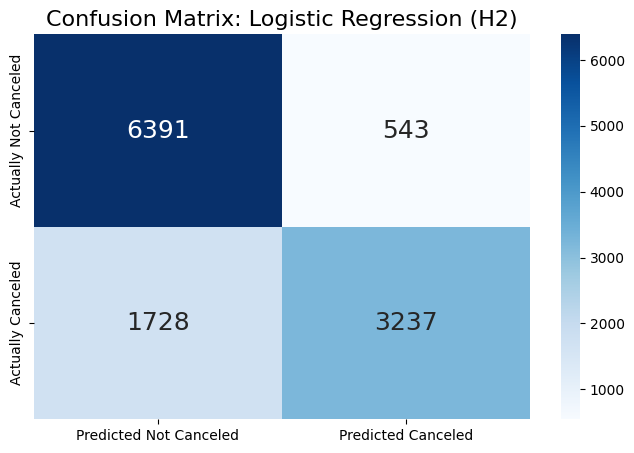

In [32]:
preds = lr.predict(X_test)
probs = lr.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, preds)
labels = ['Not Canceled', 'Canceled']

plt.figure(figsize=(8,5))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=['Predicted ' + l for l in labels],
            yticklabels=['Actually ' + l for l in labels], annot_kws={'size': 18})
plt.title('Confusion Matrix: Logistic Regression (H2)', fontsize=16);

TN, FP, FN, TP = cm.ravel()
print(f'Correctly classified:                              {(TP+TN)/cm.sum():.1%}')
print(f'Canceled bookings correctly classified (recall):   {TP/(TP+FN):.1%}')
print(f'Not canceled correctly classified (specificity):   {TN/(TN+FP):.1%}')
print(f'Predicted canceled that were canceled (precision): {TP/(TP+FP):.1%}')
print(f'Predicted not canceled that were kept (NPV):       {TN/(TN+FN):.1%}')

In [33]:
print(classification_report(y_test, preds, target_names=labels, digits=3))

              precision    recall  f1-score   support

Not Canceled      0.787     0.922     0.849      6934
    Canceled      0.856     0.652     0.740      4965

    accuracy                          0.809     11899
   macro avg      0.822     0.787     0.795     11899
weighted avg      0.816     0.809     0.804     11899

